# Sprint 3 — Analyse des disparités de l'espérance de vie

## LEP-14 | Identification des pays aux espérances de vie les plus élevées et les plus faibles

**Projet :** WHO Life Expectancy — Analyse des facteurs associés à l'espérance de vie  
**Période étudiée :** 2000–2015  
**User Story :** LEP-14  
**Branche Git :** `feature/LEP-14-classement-pays`  
**Environnement :** Python — Jupyter Notebook

---

### Objectif de l'analyse

Identifier les pays présentant les espérances de vie les plus élevées et les plus faibles pour une année de référence commune, afin de mettre en évidence les disparités internationales.

### Question analytique

**Quels pays affichent les espérances de vie les plus élevées et les plus faibles pour une même année ?**

### Source des données

L'analyse repose sur le jeu de données fiabilisé lors du Sprint 2, intégrant les corrections et les enrichissements réalisés à partir de sources officielles.

**Fichier utilisé :** `data/processed/life_expectancy_fiabilise.csv`

### Démarche analytique

1. Charger et vérifier les données nécessaires à la User Story.
2. Déterminer et justifier une année de référence commune.
3. Identifier les pays aux espérances de vie les plus élevées et les plus faibles.
4. Mesurer et visualiser les écarts observés.
5. Interpréter les résultats et documenter les limites de l'analyse.

### 3.1. Chargement des données et sélection des variables d'analyse

In [27]:

# Importer les bibliothèques nécessaires
from pathlib import Path
import pandas as pd
import numpy as np
import shutil # Importer le module de copie de fichiers
import re
import matplotlib.pyplot as plt



In [28]:
# Préparation des dossiers pour l'importation des données

# Définir le répertoire principal des données
DATA_DIR = Path("../data")

# Définir les sous-dossiers du projet
PROCESSED_DIR = DATA_DIR / "processed"

# Charger le fichier original 
df3 = pd.read_csv(PROCESSED_DIR / "life_expectancy_fiabilise.csv")

# Créer une copie indépendante pour les transformations
df4 = df3.copy(deep=True)   # Copie profonde pour isoler les données de travail et préserver le DataFrame d'origine (df3)

# Controle de chargement

df4.head()


,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,hepatitis_b,measles,under_five_deaths,...,hiv_aids,gdp,population,thinness_10_19_years,thinness_5_9_years,income_composition_of_resources,schooling,iso3,health_expenditure_pc_usd,overweight_adults_pct_oms
0,Afghanistan,2015,Developing,62.270,263.0,62,0.01,64.0,1154,83,...,0.1,565.569730,33831764.0,17.2,17.3,0.479,10.1,AFG,59.919605,37.67
1,Afghanistan,2014,Developing,62.260,271.0,64,0.01,62.0,492,86,...,0.1,625.054942,32792523.0,17.5,17.5,0.476,10.0,AFG,60.049511,36.17
2,Afghanistan,2013,Developing,62.188,268.0,66,0.01,64.0,430,89,...,0.1,637.087099,31622704.0,17.7,17.7,0.470,9.9,AFG,56.160435,34.71
3,Afghanistan,2012,Developing,61.735,272.0,69,0.01,67.0,2787,93,...,0.1,651.417134,30560034.0,17.9,18.0,0.463,9.8,AFG,52.452473,33.28
4,Afghanistan,2011,Developing,61.250,275.0,71,0.01,68.0,3013,97,...,0.1,606.694676,29347708.0,18.2,18.2,0.454,9.5,AFG,52.187218,31.89


In [29]:
# Sélection des variables d'analyse
variables = ["country", "life_expectancy", "year"]
df = df4[variables]
df.head()

,country,life_expectancy,year
0,Afghanistan,62.270,2015
1,Afghanistan,62.260,2014
2,Afghanistan,62.188,2013
3,Afghanistan,61.735,2012
4,Afghanistan,61.250,2011


### 3.2. Examen des variables d'analyse

In [30]:
# structure des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   country          2938 non-null   object 
 1   life_expectancy  2936 non-null   float64
 2   year             2938 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 69.0+ KB


In [31]:
# Données manquantes

missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_summary = pd.DataFrame({
"Missing Count": missing_counts,
"Missing Percentage (%)": missing_percent.round(2)
})

missing_summary

,Missing Count,Missing Percentage (%)
country,0,0.00
life_expectancy,2,0.07
year,0,0.00


Constat : parmi les 2 938 observations, seules deux ne disposent pas d'une valeur d'espérance de vie. Le taux de données manquantes est donc très faible pour les variables nécessaires à cette analyse.

In [32]:
# Calculer le taux de valeurs manquantes de l'espérance de vie par pays
taux_par_pays = (
    df.groupby("country")["life_expectancy"]
      .apply(lambda s: s.isna().mean() * 100)
      .rename("taux_pct")
      .reset_index()
)

# Afficher uniquement les pays présentant des valeurs manquantes
taux_par_pays[taux_par_pays["taux_pct"] > 0]

,country,taux_pct
38,Cook Islands,100.0
124,Niue,100.0


In [33]:
# Examiner la disponibilité de l'espérance de vie selon l'année
couverture_annuelle = (
    df.groupby("year")
      .agg(
          nombre_pays=("country", "nunique"),
          valeurs_disponibles=("life_expectancy", "count"),
          valeurs_manquantes=("life_expectancy", lambda s: s.isna().sum())
      )
      .reset_index()
)

display(couverture_annuelle)

,year,nombre_pays,valeurs_disponibles,valeurs_manquantes
0,2000,183,183,0
1,2001,183,183,0
2,2002,183,183,0
3,2003,183,183,0
4,2004,183,183,0
5,2005,183,183,0
6,2006,183,183,0
7,2007,183,183,0
8,2008,183,183,0
9,2009,183,183,0


**Constat :** L'examen de la disponibilité des données montre que 183 pays disposent d'une valeur d'espérance de vie pour chacune des années de 2000 à 2012, ainsi que pour 2014 et 2015. L'année 2013 se distingue avec 193 pays représentés, dont 191 présentent une valeur d'espérance de vie renseignée. Cette différence s'explique par la présence de dix pays supplémentaires disposant uniquement d'une observation en 2013. Parmi ces derniers, les Îles Cook et Niue présentent encore une valeur manquante.

La couverture annuelle du jeu de données n'est donc pas parfaitement uniforme. Bien que 2013 offre la couverture géographique la plus étendue, avec 191 pays exploitables, cette particularité doit être prise en compte pour éviter que les différences de couverture influencent les comparaisons entre années.

**Décision méthodologique :** Nous retenons trois années de référence, **2000, 2013 et 2015**, afin d'examiner les disparités d'espérance de vie au début, à une année intermédiaire et à la fin de la période étudiée. L'analyse principale portera sur les **183 pays disposant d'observations pour l'ensemble de la période 2000–2015**, afin de maintenir un périmètre géographique constant et de rendre les comparaisons plus cohérentes.

Pour 2013, nous réaliserons également une analyse complémentaire sur les **191 pays disposant d'une valeur d'espérance de vie**, afin d'évaluer si l'ajout des huit pays supplémentaires modifie les classements et l'ampleur des écarts observés.

Cette approche permettra de comparer les disparités à trois moments distincts, sans prétendre décrire leur évolution continue entre ces années, qui sera étudiée dans une User Story consacrée aux tendances temporelles.

### 3.3. Préparation des sous-ensembles d'analyse

In [34]:
#Identification des 183 pays du panel commun
# Définir la période étudiée
annees_attendues = set(range(2000, 2016))

# Identifier les années disponibles pour chaque pays
annees_par_pays = df.groupby("country")["year"].agg(set)

# Retenir les pays disposant de toutes les années attendues
pays_communs = annees_par_pays[
    annees_par_pays.apply(lambda annees: annees_attendues.issubset(annees))
].index

# Vérifier le résultat
print("Nombre de pays du panel commun :", len(pays_communs))
print("Nombre de pays exclus :", df["country"].nunique() - len(pays_communs))

#range(2000, 2016) définit les 16 années attendues.
#groupby("country") regroupe les observations par pays.
#agg(set) récupère les années présentes pour chaque pays, sans répétition.
#issubset() vérifie que toutes les années attendues sont représentées.
#.index récupère les noms des pays satisfaisant cette condition.

Nombre de pays du panel commun : 183
Nombre de pays exclus : 10


In [35]:
#Sélection des observations pour 2000, 2013 et 2015
# Définir les années de référence
annees_reference = [2000, 2013, 2015]

# Sélectionner les pays communs et les années retenues
df_comparaison = df.loc[
    df["country"].isin(pays_communs)
    & df["year"].isin(annees_reference)
].copy()

# Vérifier la répartition des observations par année
print("Dimensions :", df_comparaison.shape)

print("\nNombre d'observations par année :")
print(df_comparaison.groupby("year").size())

print("\nValeurs manquantes de l'espérance de vie :")
print(
    df_comparaison.groupby("year")["life_expectancy"]
    .apply(lambda s: s.isna().sum())
)


Dimensions : (549, 3)

Nombre d'observations par année :
year
2000    183
2013    183
2015    183
dtype: int64

Valeurs manquantes de l'espérance de vie :
year
2000    0
2013    0
2015    0
Name: life_expectancy, dtype: int64


In [36]:
# Constitution du panel élargi de 2013 (191 pays)
# Sélectionner toutes les observations de 2013
df_2013_elargi = df.loc[
    (df["year"] == 2013)
    & (df["life_expectancy"].notna())
].copy()

# Vérifier la couverture du panel élargi
print("Dimensions :", df_2013_elargi.shape)
print("Nombre de pays :", df_2013_elargi["country"].nunique())

# Identifier les pays supplémentaires par rapport au panel commun
pays_supplementaires = sorted(
    set(df_2013_elargi["country"]) - set(pays_communs)
)

print("\nNombre de pays supplémentaires :", len(pays_supplementaires))
print("\nPays supplémentaires :")
print(pays_supplementaires)



Dimensions : (191, 3)
Nombre de pays : 191

Nombre de pays supplémentaires : 8

Pays supplémentaires :
['Dominica', 'Marshall Islands', 'Monaco', 'Nauru', 'Palau', 'Saint Kitts and Nevis', 'San Marino', 'Tuvalu']


In [37]:
# Validation des sous-ensembles d'analyse

# Vérifier la structure et la complétude des deux échantillons
print("Panel commun :", df_comparaison.shape)
print("Panel élargi 2013 :", df_2013_elargi.shape)

# Vérifier les doublons sur la clé pays-année
print("\nDoublons dans le panel commun :",
      df_comparaison.duplicated(["country", "year"]).sum())

print("Doublons dans le panel élargi :",
      df_2013_elargi.duplicated(["country", "year"]).sum())

# Vérifier les valeurs manquantes
print("\nValeurs manquantes dans le panel commun :")
print(df_comparaison.isna().sum())

print("\nValeurs manquantes dans le panel élargi :")
print(df_2013_elargi.isna().sum())

Panel commun : (549, 3)
Panel élargi 2013 : (191, 3)

Doublons dans le panel commun : 0
Doublons dans le panel élargi : 0

Valeurs manquantes dans le panel commun :
country            0
life_expectancy    0
year               0
dtype: int64

Valeurs manquantes dans le panel élargi :
country            0
life_expectancy    0
year               0
dtype: int64


**Constat :** Les contrôles effectués confirment que le panel commun comprend 549 observations, correspondant à 183 pays étudiés pour les années 2000, 2013 et 2015. L'échantillon élargi de 2013 comprend quant à lui 191 observations. Aucun doublon sur la combinaison pays–année ni aucune valeur manquante n'a été détecté dans les variables retenues.

**Décision :** Les deux ensembles sont considérés comme prêts pour l'analyse. Le panel commun servira aux comparaisons entre les trois années de référence, tandis que l'échantillon élargi de 2013 permettra d'évaluer l'influence des huit pays supplémentaires sur les classements et les disparités d'espérance de vie.

### 3.4. Analyse comparative des espérances de vie extrêmes

#### 3.4.1. Identification des pays aux espérances de vie les plus élevées et les plus faibles

Ojectif : identifier les dix pays présentant les espérances de vie les plus élevées et les dix pays présentant les valeurs les plus faibles, pour chacune des trois années de référence, à partir du panel commun.

In [38]:
# Identifier les 10 pays ayant les espérances de vie les plus élevées
# pour chacune des trois années de référence

top_10 = (
    df_comparaison
    .sort_values(
        ["year", "life_expectancy"],
        ascending=[True, False]
    )
    .groupby("year")
    .head(10)
    .reset_index(drop=True)
)

display(top_10)




#sort_values() trie les observations par année, puis par espérance de vie décroissante.
#ascending=[True, False] signifie : années croissantes et espérances de vie décroissantes.
#groupby("year") regroupe les observations par année.
#head(10) conserve les dix premières observations de chaque groupe.
#reset_index(drop=True) réinitialise l'index pour faciliter la lecture.

,country,life_expectancy,year
0,Japan,81.076098,2000
1,Italy,79.778049,2000
2,Switzerland,79.680488,2000
3,Iceland,79.653659,2000
4,Sweden,79.643902,2000
5,Australia,79.234146,2000
6,Canada,79.166829,2000
7,France,79.056098,2000
8,Spain,78.965854,2000
9,Israel,78.953659,2000


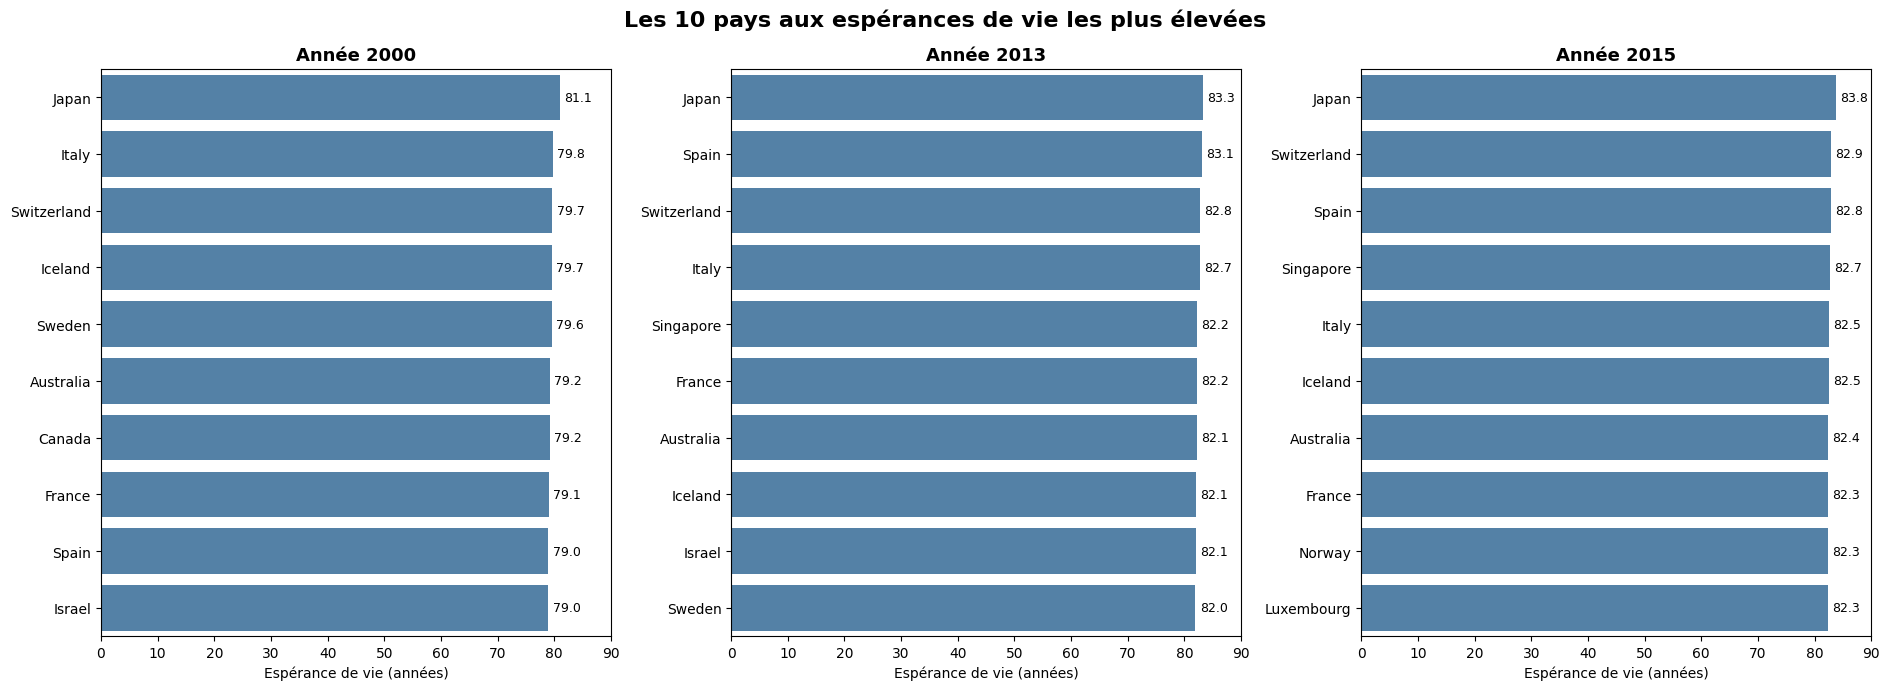

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Créer un graphique pour chacune des trois années
fig, axes = plt.subplots(1, 3, figsize=(19, 7), sharex=True)

for ax, annee in zip(axes, [2000, 2013, 2015]):

    # Sélectionner les dix premiers pays de l'année
    # et les classer par espérance de vie décroissante
    donnees = (
        top_10[top_10["year"] == annee]
        .sort_values("life_expectancy", ascending=False)
    )

    # Créer le diagramme à barres horizontales
    sns.barplot(
        data=donnees,
        x="life_expectancy",
        y="country",
        order=donnees["country"].tolist(),
        ax=ax,
        color="steelblue"
    )

    # Personnaliser les titres et les axes
    ax.set_title(f"Année {annee}", fontsize=13, weight="bold")
    ax.set_xlabel("Espérance de vie (années)")
    ax.set_ylabel("")
    ax.set_xlim(0, 90)

    # Afficher les valeurs à une décimale
    for conteneur in ax.containers:
        ax.bar_label(
            conteneur,
            fmt="%.1f",
            padding=3,
            fontsize=9
        )

# Ajouter le titre général
fig.suptitle(
    "Les 10 pays aux espérances de vie les plus élevées",
    fontsize=16,
    weight="bold"
)

# Ajuster les espacements
plt.tight_layout()

# Afficher le graphique
plt.show()

Analyse Top 10 des espérances de vie (2000, 2013 et 2015)

**Constat :** Le classement des dix pays présentant les espérances de vie les plus élevées, réalisé sur un panel commun de 183 pays, montre que le Japon occupe la première position pour les trois années étudiées. Son espérance de vie passe de **81,08 ans en 2000 à 83,33 ans en 2013, puis à 83,79 ans en 2015**, soit une augmentation de 2,72 ans entre 2000 et 2015.

En 2000, le Japon se distingue avec 81,08 ans, devant l'Italie (79,78 ans) et la Suisse (79,68 ans). En 2013, il conserve la première position, suivi de l'Espagne (83,08 ans) et de la Suisse (82,80 ans). En 2015, il reste en tête devant la Suisse (82,90 ans) et l'Espagne (82,83 ans).

La composition du Top 10 présente une certaine stabilité : **six pays figurent dans les trois classements**, à savoir le Japon, l'Italie, la Suisse, l'Islande, l'Australie et la France. D'autres changements sont observés, notamment l'apparition de Singapour parmi les dix premiers en 2013 et 2015, alors qu'il n'y figurait pas en 2000.

**Analyse graphique :** Les diagrammes à barres horizontales montrent une progression générale des valeurs les plus élevées entre les années sélectionnées. En 2000, les espérances de vie du Top 10 s'étendent d'environ 78,95 à 81,08 ans, contre 81,96 à 83,33 ans en 2013 et 82,29 à 83,79 ans en 2015.

L'écart entre la première et la dixième position passe ainsi d'environ **2,12 ans en 2000 à 1,38 an en 2013, puis à 1,50 an en 2015**. Les pays du Top 10 présentent donc des valeurs relativement rapprochées, avec un resserrement de l'écart entre les extrémités du classement par rapport à 2000.

Ces résultats indiquent une progression des espérances de vie les plus élevées et une certaine stabilité des pays occupant les premières positions. 

### 3.4.2. Identification des dix pays aux espérances de vie les plus faibles

In [45]:
# Identifier les 10 pays aux espérances de vie les plus faibles
# pour chacune des trois années de référence

bottom_10 = (
    df_comparaison
    .sort_values(
        ["year", "life_expectancy"],
        ascending=[True, True]
    )
    .groupby("year")
    .head(10)
    .reset_index(drop=True)
)

display(bottom_10)

,country,life_expectancy,year
0,Sierra Leone,44.834,2000
1,Zimbabwe,46.034,2000
2,Malawi,46.170,2000
3,Angola,46.501,2000
4,Zambia,46.577,2000
5,Central African Republic,46.609,2000
6,Nigeria,47.143,2000
7,South Sudan,47.591,2000
8,Burundi,47.617,2000
9,Swaziland,47.627,2000


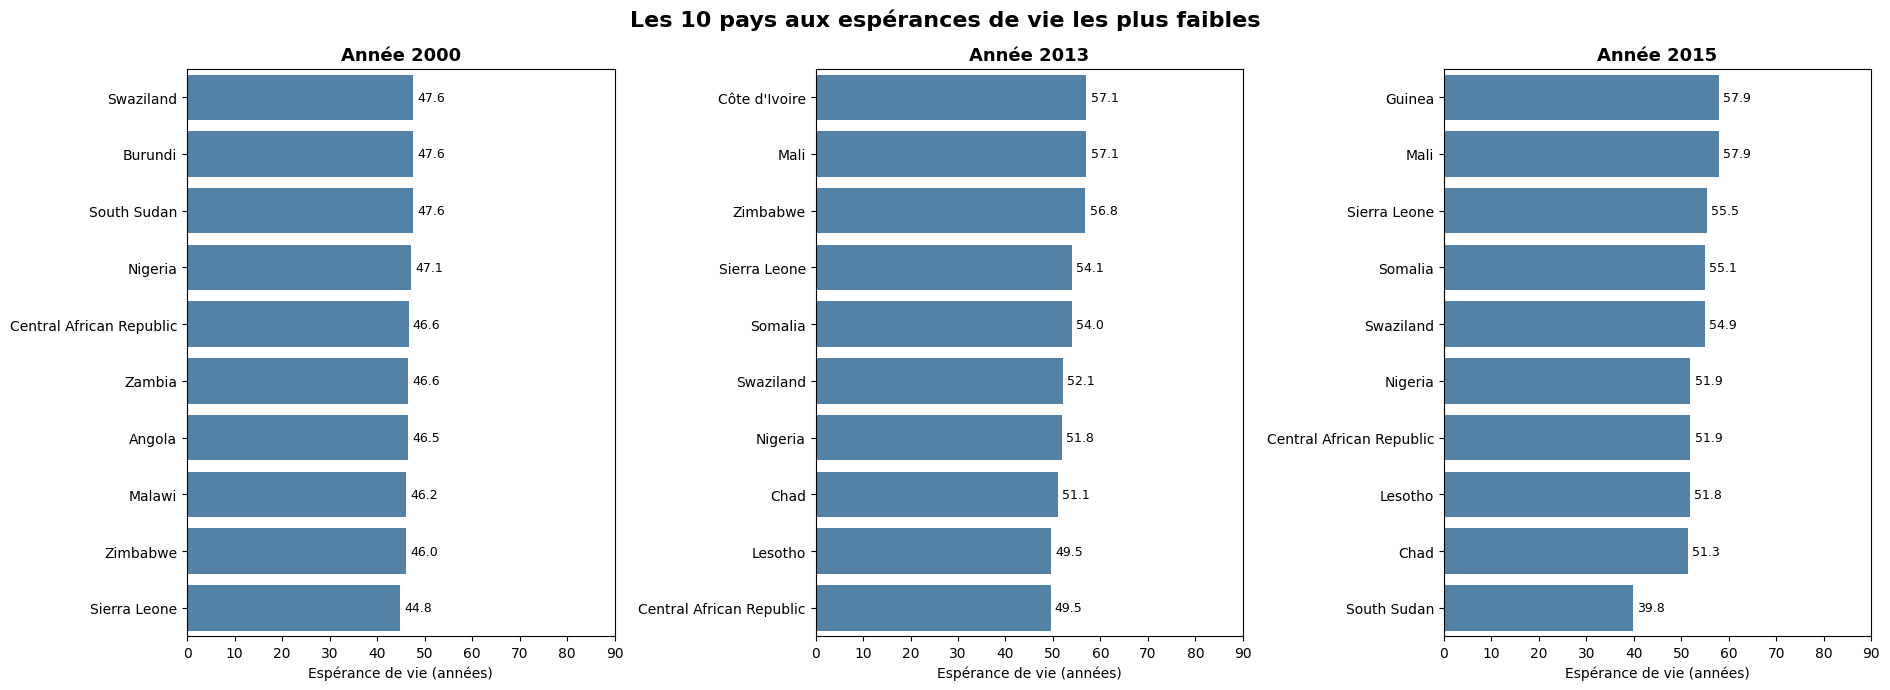

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Créer un graphique pour chacune des trois années
fig, axes = plt.subplots(1, 3, figsize=(19, 7), sharex=True)

for ax, annee in zip(axes, [2000, 2013, 2015]):

    # Sélectionner les 10 pays aux espérances de vie les plus faibles
    # puis les afficher par ordre décroissant
    donnees = (
        bottom_10[bottom_10["year"] == annee]
        .sort_values("life_expectancy", ascending=False)
    )

    # Créer le diagramme à barres horizontales
    sns.barplot(
        data=donnees,
        x="life_expectancy",
        y="country",
        order=donnees["country"].tolist(),
        ax=ax,
        color="steelblue"
    )

    # Personnaliser les axes
    ax.set_title(f"Année {annee}", fontsize=13, weight="bold")
    ax.set_xlabel("Espérance de vie (années)")
    ax.set_ylabel("")
    ax.set_xlim(0, 90)

    # Afficher les valeurs sur les barres
    for conteneur in ax.containers:
        ax.bar_label(
            conteneur,
            fmt="%.1f",
            padding=3,
            fontsize=9
        )

# Ajouter le titre général
fig.suptitle(
    "Les 10 pays aux espérances de vie les plus faibles",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()
plt.show()

Bottom 10 des espérances de vie (2000, 2013 et 2015)

**Constat :** Le classement des dix pays présentant les espérances de vie les plus faibles, réalisé sur le panel commun de 183 pays, révèle des différences importantes entre les trois années étudiées.

En 2000, la Sierra Leone présente l'espérance de vie la plus faible, avec 44,83 ans, suivie du Zimbabwe (46,03 ans) et du Malawi (46,17 ans). Les dix pays du classement affichent des valeurs comprises entre 44,83 et 47,63 ans, soit un écart relativement limité de 2,79 ans.

En 2013, la République centrafricaine occupe la dernière position avec 49,49 ans, suivie du Lesotho (49,55 ans) et du Tchad (51,05 ans). L'écart entre les valeurs extrêmes du Bottom 10 atteint alors 7,57 ans.

En 2015, le Soudan du Sud se distingue avec une espérance de vie de 39,76 ans, nettement inférieure à celle du Tchad (51,32 ans), qui présente la deuxième valeur la plus faible. L'écart entre ces deux pays atteint 11,56 ans, tandis que celui entre les extrémités du Bottom 10 s'élève à 18,14 ans.

**Analyse graphique :** Les diagrammes à barres horizontales montrent qu'en 2000, les dix pays du classement présentent des espérances de vie relativement proches. En 2013, les valeurs sont davantage dispersées. Cette dispersion devient particulièrement marquée en 2015, principalement en raison de la faible valeur observée pour le Soudan du Sud.

Plusieurs pays apparaissent à plusieurs reprises parmi les dix derniers, notamment la Sierra Leone, le Nigeria, la République centrafricaine et le Swaziland. Leur présence répétée met en évidence la persistance de faibles niveaux d'espérance de vie dans certains pays, malgré les changements de classement.

**Interprétation :** Contrairement au Top 10, dont les valeurs restent relativement rapprochées, le Bottom 10 présente une dispersion croissante entre les trois années sélectionnées. Toutefois, cette évolution dépend fortement des observations extrêmes, particulièrement de celle du Soudan du Sud en 2015.

Ces résultats suggèrent que les situations des pays présentant les plus faibles espérances de vie sont hétérogènes. 

### 3.4.3 Calcul de l'écart entre les valeurs extrêmes

Objectif : déterminer, pour chaque année, l'espérance de vie maximale, l'espérance de vie minimale et leur différence, en utilisant notre panel commun de 183 pays.

In [48]:
# Calculer les valeurs extrêmes pour chaque année
disparites = (
    df_comparaison
    .groupby("year")["life_expectancy"]
    .agg(
        esperance_min="min",
        esperance_max="max",
        esperance_moyenne="mean",
        esperance_mediane="median"
    )
    .reset_index()
)

# Calculer l'écart entre le maximum et le minimum
disparites["ecart_extremes"] = (
    disparites["esperance_max"] - disparites["esperance_min"]
)

# Arrondir les résultats pour la présentation
display(disparites.round(2))

,year,esperance_min,esperance_max,esperance_moyenne,esperance_mediane,ecart_extremes
0,2000,44.83,81.08,66.40,69.58,36.24
1,2013,49.49,83.33,70.81,72.34,33.84
2,2015,39.76,83.79,71.20,72.82,44.04


**Constat :** L'analyse des 183 pays du panel commun montre une progression de l'espérance de vie moyenne, qui passe de 66,40 ans en 2000 à 70,81 ans en 2013, puis à 71,20 ans en 2015. La médiane suit également une tendance à la hausse, passant de 69,58 à 72,82 ans entre 2000 et 2015.

En revanche, l'écart entre les valeurs extrêmes évolue différemment. Il diminue de 36,24 ans en 2000 à 33,84 ans en 2013, avant d'augmenter à 44,04 ans en 2015. Cette augmentation est principalement liée à la valeur minimale observée au Soudan du Sud en 2015 (39,76 ans), tandis que le Japon conserve la valeur maximale (83,79 ans).

**Interprétation :** Ces résultats mettent en évidence une progression des valeurs centrales d'espérance de vie parmi les pays étudiés, mais aussi la persistance de disparités importantes. L'augmentation de l'écart entre les extrêmes en 2015 doit toutefois être interprétée avec prudence, car cet indicateur est particulièrement sensible aux observations les plus faibles et les plus élevées.

Ainsi, les résultats ne permettent pas encore de conclure à une augmentation générale des disparités entre les pays. Des mesures complémentaires, moins sensibles aux valeurs extrêmes, seront nécessaires pour préciser cette interprétation.

### Comparaison des distributions de l'espérance de vie par boxplots


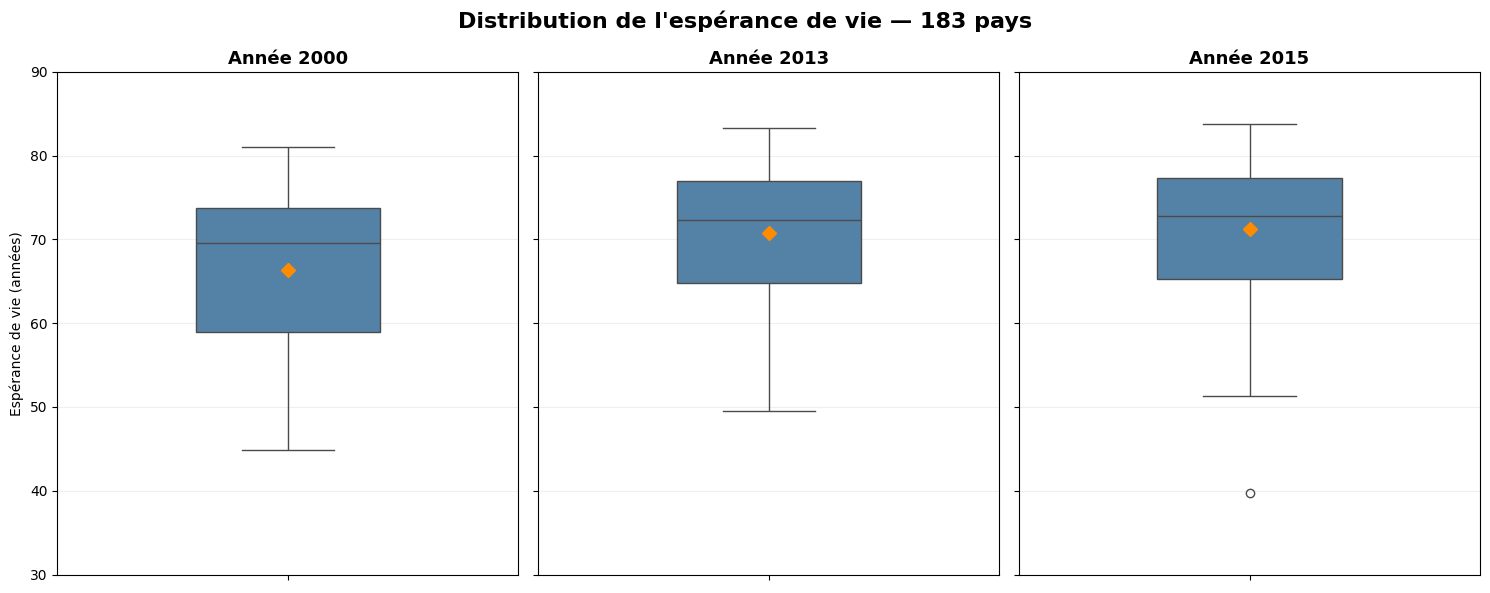

In [52]:

import matplotlib.pyplot as plt
import seaborn as sns

# Définir les années de référence
annees = [2000, 2013, 2015]

# Créer trois boxplots sur une échelle commune
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

for ax, annee in zip(axes, annees):

    # Sélectionner les 183 pays pour l'année concernée
    donnees = df_comparaison.loc[
        df_comparaison["year"] == annee
    ]

    # Créer le boxplot
    sns.boxplot(
        data=donnees,
        y="life_expectancy",
        ax=ax,
        color="steelblue",
        width=0.4,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "darkorange",
            "markeredgecolor": "darkorange",
            "markersize": 7
        }
    )

    # Personnaliser chaque graphique
    ax.set_title(f"Année {annee}", fontsize=13, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Espérance de vie (années)" if annee == 2000 else "")
    ax.set_ylim(30, 90)
    ax.grid(axis="y", alpha=0.2)

# Titre général
fig.suptitle(
    "Distribution de l'espérance de vie — 183 pays",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()
plt.show()


Analyse des distributions de l'espérance de vie  (2000, 2013 et 2015)

**Constat :** La comparaison des boxplots des 183 pays montre une progression des espérances de vie entre les trois années étudiées. La médiane passe de **69,58 ans en 2000 à 72,34 ans en 2013, puis à 72,82 ans en 2015**, soit une augmentation de 3,24 ans entre 2000 et 2015. La moyenne suit également cette progression, passant de 66,40 à 71,20 ans, soit un gain de 4,80 ans.

L'examen des boîtes montre que les 50 % de pays situés entre le premier et le troisième quartile présentent une dispersion plus importante en 2000 qu'en 2013 et 2015. La boîte de 2000 s'étend approximativement de 59 à 74 ans, alors que celles de 2013 et 2015 se situent autour de 65 à 77 ans. Les distributions centrales semblent donc s'être resserrées, tout en se déplaçant vers des niveaux d'espérance de vie plus élevés.

Les trois distributions présentent également une moyenne inférieure à la médiane. Cette différence indique que les pays ayant les espérances de vie les plus faibles contribuent à abaisser la moyenne, ce qui suggère une asymétrie vers les faibles valeurs.

En ce qui concerne les extrêmes, l'écart entre le maximum et le minimum diminue de **36,24 ans en 2000 à 33,84 ans en 2013**, avant d'atteindre **44,04 ans en 2015**. Le boxplot de 2015 se distingue notamment par une observation atypique située sous la moustache inférieure, correspondant au Soudan du Sud, avec une espérance de vie de 39,76 ans.

**Interprétation :** Ces résultats suggèrent une amélioration générale des niveaux d'espérance de vie parmi les 183 pays étudiés, accompagnée d'un resserrement de la dispersion centrale par rapport à 2000. Toutefois, cette évolution ne bénéficie pas nécessairement à tous les pays dans les mêmes proportions.

La forte augmentation de l'écart entre les extrêmes en 2015 semble principalement liée à la situation particulière du Soudan du Sud, plutôt qu'à un élargissement comparable de l'ensemble de la distribution. En effet, la boîte de 2015 reste relativement proche de celle de 2013, tandis que la valeur minimale s'en éloigne nettement.

Ainsi, les boxplots mettent en évidence **une progression des espérances de vie centrales et une réduction apparente de leur dispersion, malgré la persistance de situations nationales particulièrement défavorables**.

Ces observations concernent les trois années de référence sélectionnées et ne permettent pas, à elles seules, de décrire l'évolution continue des disparités entre 2000 et 2015.

### 3.4.4. Analyse de sensibilité : comparaison des classements de 2013 sur 183 et 191 pays

Objectif : comparer les résultats obtenus avec les 183 pays du panel commun et ceux des 191 pays disponibles en 2013, afin de déterminer si l'ajout des huit pays supplémentaires modifie les classements et les disparités observées.

In [53]:
# Sélectionner les 183 pays du panel commun pour 2013
df_2013_commun = df_comparaison.loc[
    df_comparaison["year"] == 2013
].copy()

# Regrouper les deux échantillons pour faciliter leur comparaison
echantillons_2013 = {
    "Panel commun (183 pays)": df_2013_commun,
    "Panel élargi (191 pays)": df_2013_elargi
}

# Calculer les statistiques descriptives pour chaque échantillon
resultats = []

for nom, donnees in echantillons_2013.items():

    valeurs = donnees["life_expectancy"]

    resultats.append({
        "Échantillon": nom,
        "Nombre de pays": donnees["country"].nunique(),
        "Minimum": valeurs.min(),
        "Maximum": valeurs.max(),
        "Moyenne": valeurs.mean(),
        "Médiane": valeurs.median(),
        "Q1": valeurs.quantile(0.25),
        "Q3": valeurs.quantile(0.75)
    })

# Construire le tableau comparatif
comparaison_2013 = pd.DataFrame(resultats)

# Calculer l'écart entre les extrêmes
comparaison_2013["Écart extrêmes"] = (
    comparaison_2013["Maximum"] - comparaison_2013["Minimum"]
)

display(comparaison_2013.round(2))

,Échantillon,Nombre de pays,Minimum,Maximum,Moyenne,Médiane,Q1,Q3,Écart extrêmes
0,Panel commun (183 pays),183,49.49,83.33,70.81,72.34,64.82,77.03,33.84
1,Panel élargi (191 pays),191,49.49,85.06,70.84,71.87,64.94,77.03,35.57


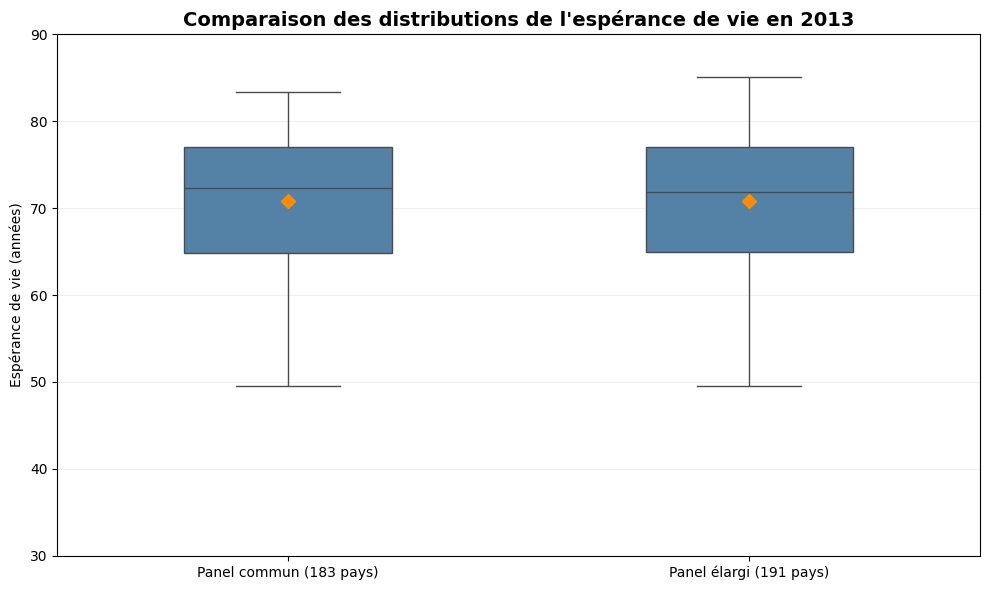

In [54]:
# Visualiser les deux distributions
import matplotlib.pyplot as plt
import seaborn as sns

# Préparer les données des deux échantillons
df_boxplots_2013 = pd.concat(
    [
        df_2013_commun.assign(
            echantillon="Panel commun (183 pays)"
        ),
        df_2013_elargi.assign(
            echantillon="Panel élargi (191 pays)"
        )
    ],
    ignore_index=True
)

# Créer les deux boxplots comparatifs
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df_boxplots_2013,
    x="echantillon",
    y="life_expectancy",
    color="steelblue",
    width=0.45,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "darkorange",
        "markeredgecolor": "darkorange",
        "markersize": 7
    },
    ax=ax
)

# Personnaliser le graphique
ax.set_title(
    "Comparaison des distributions de l'espérance de vie en 2013",
    fontsize=14,
    weight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("Espérance de vie (années)")
ax.set_ylim(30, 90)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### Analyse des résultats — Comparaison des panels de 183 et 191 pays en 2013

**Constat :** La comparaison des deux échantillons de 2013 montre que l'ajout de huit pays supplémentaires modifie certaines statistiques, mais entraîne peu de changements dans la distribution générale de l'espérance de vie.

La moyenne reste pratiquement identique, passant de 70,81 ans pour les 183 pays du panel commun à 70,84 ans pour les 191 pays du panel élargi. La médiane diminue légèrement, de 72,34 à 71,87 ans, soit une différence de 0,47 an.

Les quartiles présentent également des variations limitées. Le premier quartile passe de 64,82 à 64,94 ans, tandis que le troisième quartile demeure à 77,03 ans. L'écart interquartile diminue ainsi légèrement, de 12,21 à 12,09 ans.

En revanche, la valeur maximale passe de 83,33 à 85,06 ans, tandis que le minimum reste inchangé à 49,49 ans. L'écart entre les extrêmes augmente donc de 33,84 à 35,57 ans, soit une différence de 1,73 an.

**Analyse graphique :** Les deux boxplots présentent des distributions très similaires. Les boîtes occupent presque les mêmes intervalles, les médianes restent proches et les moyennes sont pratiquement superposées. Cela confirme visuellement que l'ajout des huit pays modifie peu la répartition centrale des espérances de vie.

La principale différence apparaît au niveau de la valeur maximale, légèrement plus élevée dans le panel élargi. Cette modification n'entraîne toutefois pas d'élargissement notable de la boîte ni de changement important dans la dispersion centrale.

**Interprétation :** Ces résultats indiquent que les conclusions descriptives concernant les niveaux centraux et la dispersion de l'espérance de vie en 2013 restent globalement stables lorsque la couverture passe de 183 à 191 pays.

Toutefois, l'augmentation du maximum montre que l'élargissement géographique peut modifier les premières positions du classement et l'écart entre les valeurs extrêmes, même lorsque les statistiques centrales restent presque inchangées.

Cette analyse de sensibilité confirme donc l'intérêt de conserver le panel commun de 183 pays pour les comparaisons entre années, tout en utilisant le panel élargi de 191 pays pour présenter une couverture géographique plus complète de la situation en 2013.

### 3.4.5. Identification des changements dans les classements Top 10 et Bottom 10

Objectif : déterminer si les huit pays supplémentaires entrent dans les classements et identifier les pays dont la position change.

In [55]:
# Comparer les classements Top 10 et Bottom 10 des deux panels

for classement, ordre in [("TOP 10", False), ("BOTTOM 10", True)]:

    # Classement des 183 pays
    commun = (
        df_2013_commun
        .sort_values("life_expectancy", ascending=ordre)
        .head(10)
        .reset_index(drop=True)
    )

    # Classement des 191 pays
    elargi = (
        df_2013_elargi
        .sort_values("life_expectancy", ascending=ordre)
        .head(10)
        .reset_index(drop=True)
    )

    # Ajouter les rangs
    commun["rang"] = range(1, 11)
    elargi["rang"] = range(1, 11)

    # Identifier les nouveaux pays du classement
    nouveaux_pays = set(elargi["country"]) - set(commun["country"])

    # Identifier les pays sortis du classement
    pays_sortis = set(commun["country"]) - set(elargi["country"])

    print(f"\n--- {classement} ---")

    print("Nouveaux pays dans le classement :", sorted(nouveaux_pays))
    print("Pays sortis du classement :", sorted(pays_sortis))

    # Comparer les rangs des pays présents dans les deux classements
    comparaison_rangs = commun[
        ["country", "rang"]
    ].merge(
        elargi[["country", "rang"]],
        on="country",
        suffixes=("_183", "_191")
    )

    comparaison_rangs["variation_rang"] = (
        comparaison_rangs["rang_191"]
        - comparaison_rangs["rang_183"]
    )

    display(comparaison_rangs.sort_values("rang_183"))


--- TOP 10 ---
Nouveaux pays dans le classement : ['Monaco', 'San Marino']
Pays sortis du classement : ['Israel', 'Sweden']


,country,rang_183,rang_191,variation_rang
0,Japan,1,3,2
1,Spain,2,4,2
2,Switzerland,3,5,2
3,Italy,4,6,2
4,Singapore,5,7,2
5,France,6,8,2
6,Australia,7,9,2
7,Iceland,8,10,2



--- BOTTOM 10 ---
Nouveaux pays dans le classement : []
Pays sortis du classement : []


,country,rang_183,rang_191,variation_rang
0,Central African Republic,1,1,0
1,Lesotho,2,2,0
2,Chad,3,3,0
3,Nigeria,4,4,0
4,Swaziland,5,5,0
5,Somalia,6,6,0
6,Sierra Leone,7,7,0
7,Zimbabwe,8,8,0
8,Mali,9,9,0
9,Côte d'Ivoire,10,10,0


Analyse des changements de classement — Panels de 183 et 191 pays en 2013

**Constat :** La comparaison des classements de 2013 montre que l'ajout des huit pays supplémentaires modifie le Top 10 des espérances de vie les plus élevées. Deux nouveaux pays, Monaco et Saint-Marin, intègrent les premières positions, entraînant la sortie d'Israël et de la Suède.

Le Japon, qui occupait la première position dans le panel de 183 pays, passe à la troisième place dans le panel élargi. Les huit pays conservés dans les deux Top 10 reculent chacun de deux positions. Cette modification s'accompagne d'une augmentation de l'espérance de vie maximale, qui passe de 83,33 à 85,06 ans.

En revanche, le Bottom 10 demeure entièrement inchangé. Aucun des huit pays supplémentaires n'entre parmi les dix pays présentant les espérances de vie les plus faibles, et les positions des pays déjà présents restent identiques.

**Interprétation :** Ces résultats montrent que l'élargissement de la couverture géographique influence principalement les valeurs les plus élevées de la distribution. L'intégration de Monaco et de Saint-Marin modifie les premières positions du classement et augmente l'écart entre les extrêmes de 1,73 an.

Toutefois, ces changements ne s'accompagnent pas de modifications importantes des statistiques centrales, comme l'ont montré les moyennes, les médianes et les boxplots comparatifs.

L'analyse de sensibilité indique ainsi que **les conclusions générales sur la distribution de l'espérance de vie en 2013 restent relativement stables, mais que les classements des pays les mieux positionnés sont sensibles à la couverture géographique retenue**.

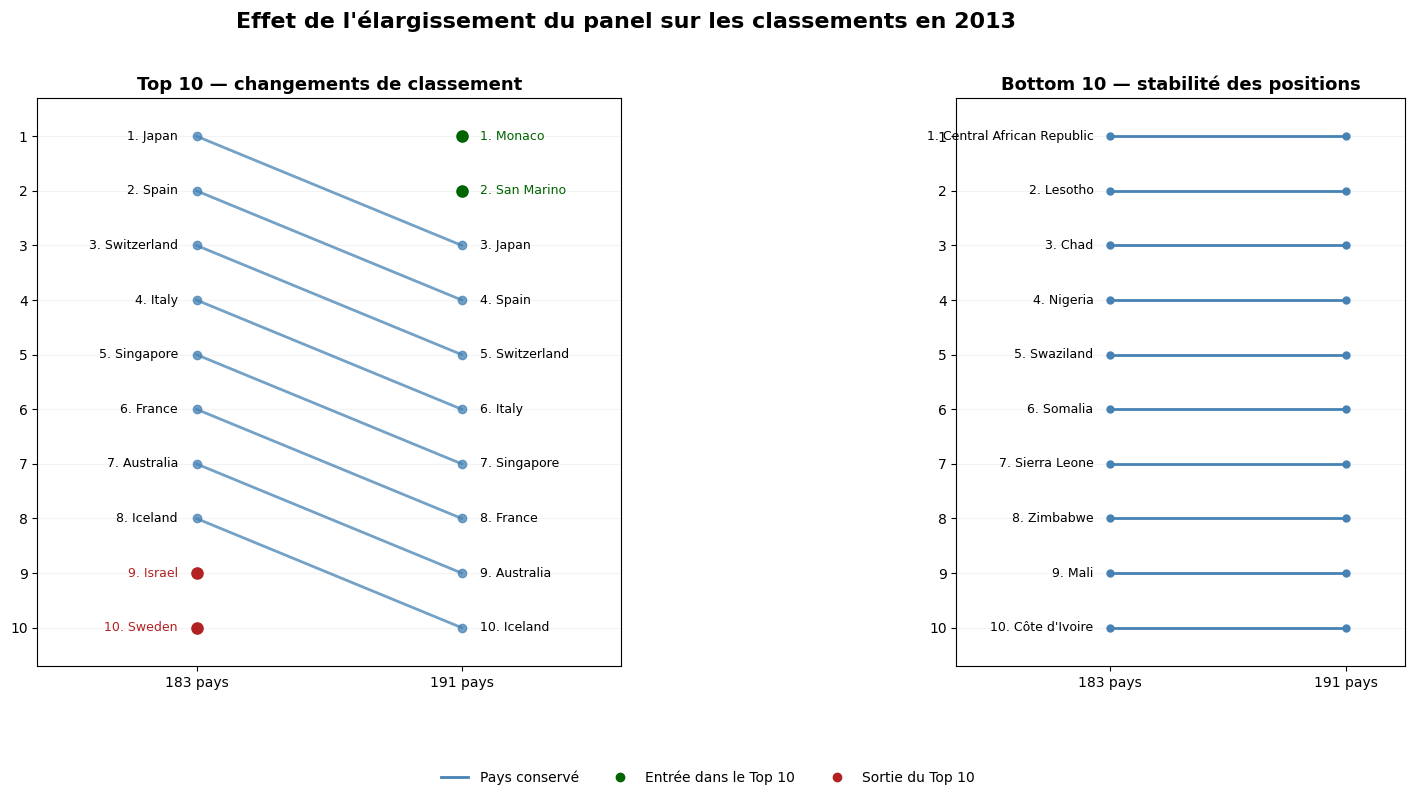

In [58]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Construire les classements à partir des deux échantillons
def classement(df, croissant=False):
    resultat = (
        df.sort_values(
            ["life_expectancy", "country"],
            ascending=[croissant, True]
        )
        .head(10)
        .reset_index(drop=True)
        .copy()
    )
    resultat["rang"] = range(1, 11)
    return resultat

top_183 = classement(df_2013_commun)
top_191 = classement(df_2013_elargi)

bottom_183 = classement(df_2013_commun, croissant=True)
bottom_191 = classement(df_2013_elargi, croissant=True)

# Préparer les correspondances pays-rang
rangs_183 = dict(zip(top_183["country"], top_183["rang"]))
rangs_191 = dict(zip(top_191["country"], top_191["rang"]))

pays_communs_top = set(rangs_183) & set(rangs_191)
entrees = set(rangs_191) - set(rangs_183)
sorties = set(rangs_183) - set(rangs_191)

# Créer deux graphiques accolés
fig, axes = plt.subplots(
    1, 2, figsize=(19, 8),
    gridspec_kw={"width_ratios": [1.3, 1]}
)

# ===================================================
# GRAPHIQUE 1 — TOP 10 : ENTRÉES, SORTIES ET RANGS
# ===================================================

ax = axes[0]

# Relier les pays présents dans les deux classements
for pays in pays_communs_top:
    ax.plot(
        [0, 1],
        [rangs_183[pays], rangs_191[pays]],
        color="steelblue",
        linewidth=2,
        alpha=0.75,
        marker="o",
        markersize=6
    )

# Afficher les pays du panel commun
for _, ligne in top_183.iterrows():
    pays = ligne["country"]
    rang = ligne["rang"]

    ax.text(
        -0.07, rang,
        f"{rang}. {pays}",
        ha="right", va="center",
        fontsize=9,
        color="firebrick" if pays in sorties else "black"
    )

    if pays in sorties:
        ax.scatter(0, rang, color="firebrick", s=65, zorder=4)

# Afficher les pays du panel élargi
for _, ligne in top_191.iterrows():
    pays = ligne["country"]
    rang = ligne["rang"]

    ax.text(
        1.07, rang,
        f"{rang}. {pays}",
        ha="left", va="center",
        fontsize=9,
        color="darkgreen" if pays in entrees else "black"
    )

    if pays in entrees:
        ax.scatter(1, rang, color="darkgreen", s=65, zorder=4)

ax.set_title(
    "Top 10 — changements de classement",
    fontsize=13, weight="bold"
)
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(10.7, 0.3)
ax.set_xticks([0, 1])
ax.set_xticklabels(["183 pays", "191 pays"])
ax.set_yticks(range(1, 11))
ax.grid(axis="y", alpha=0.15)

# ===================================================
# GRAPHIQUE 2 — BOTTOM 10 : STABILITÉ DES RANGS
# ===================================================

ax = axes[1]

# Les rangs du panel commun servent de référence
for _, ligne in bottom_183.iterrows():
    pays = ligne["country"]
    rang = ligne["rang"]

    # Vérifier le rang dans le panel élargi
    rang_elargi = bottom_191.loc[
        bottom_191["country"] == pays, "rang"
    ]

    if not rang_elargi.empty:
        nouveau_rang = int(rang_elargi.iloc[0])

        ax.plot(
            [0, 1],
            [rang, nouveau_rang],
            color="steelblue",
            linewidth=2,
            marker="o",
            markersize=5
        )

    ax.text(
        -0.07, rang,
        f"{rang}. {pays}",
        ha="right", va="center",
        fontsize=9
    )

ax.set_title(
    "Bottom 10 — stabilité des positions",
    fontsize=13, weight="bold"
)
ax.set_xlim(-0.65, 1.25)
ax.set_ylim(10.7, 0.3)
ax.set_xticks([0, 1])
ax.set_xticklabels(["183 pays", "191 pays"])
ax.set_yticks(range(1, 11))
ax.grid(axis="y", alpha=0.15)

# ===================================================
# PRÉSENTATION GÉNÉRALE
# ===================================================

fig.suptitle(
    "Effet de l'élargissement du panel sur les classements en 2013",
    fontsize=16,
    weight="bold"
)

legende = [
    Line2D([0], [0], color="steelblue", lw=2,
           label="Pays conservé"),
    Line2D([0], [0], marker="o", color="darkgreen",
           linestyle="", label="Entrée dans le Top 10"),
    Line2D([0], [0], marker="o", color="firebrick",
           linestyle="", label="Sortie du Top 10")
]

fig.legend(
    handles=legende,
    loc="lower center",
    ncol=3,
    frameon=False
)

fig.subplots_adjust(
    left=0.19,
    right=0.91,
    top=0.87,
    bottom=0.16,
    wspace=0.65
)

plt.show()


**Analyse graphique :** Le diagramme de correspondance montre que l'ajout des huit pays supplémentaires en 2013 entraîne l'entrée de Monaco et de Saint-Marin aux deux premières positions du Top 10, provoquant un recul de deux rangs pour les huit pays conservés dans le classement. Les lignes parallèles traduisent ce déplacement identique, sans modification de leur ordre relatif.

À l'inverse, les lignes horizontales du Bottom 10 montrent que les dix pays conservent exactement les mêmes positions dans les deux échantillons.

**Interprétation :** L'élargissement du panel influence donc principalement le classement des pays aux espérances de vie les plus élevées, sans modifier celui des pays aux valeurs les plus faibles. Les changements observés résultent de l'intégration de nouveaux pays et non d'une évolution de leur espérance de vie, puisque les deux classements concernent la même année, 2013.

## 4. Synthèse des résultats et conclusion

### 4.1. Principaux résultats

L'analyse des espérances de vie en 2000, 2013 et 2015, réalisée sur un panel commun de 183 pays, met en évidence plusieurs constats.

**Premièrement, les pays occupant les premières positions présentent des niveaux d'espérance de vie relativement élevés et une certaine stabilité dans les classements.** Le Japon conserve la première place pour les trois années étudiées, avec une espérance de vie passant de 81,08 ans en 2000 à 83,79 ans en 2015.

À l'inverse, les pays présentant les espérances de vie les plus faibles changent davantage selon les années. La Sierra Leone occupe la dernière position en 2000 (44,83 ans), la République centrafricaine en 2013 (49,49 ans) et le Soudan du Sud en 2015 (39,76 ans).

**Deuxièmement, les distributions montrent une progression des valeurs centrales.** Entre 2000 et 2015, la moyenne des espérances de vie des 183 pays augmente de 66,40 à 71,20 ans, tandis que la médiane passe de 69,58 à 72,82 ans.

Les boxplots suggèrent également un resserrement de la dispersion centrale par rapport à 2000. Toutefois, des situations nationales particulièrement défavorables persistent.

**Troisièmement, l'écart entre les valeurs extrêmes demeure important.** Il atteint 36,24 ans en 2000, 33,84 ans en 2013 et 44,04 ans en 2015. Cette dernière valeur est fortement influencée par la faible espérance de vie observée au Soudan du Sud.

Enfin, **l'analyse de sensibilité réalisée pour 2013 montre que la couverture géographique influence les classements des pays les mieux positionnés**. L'ajout de huit pays permet notamment à Monaco et à Saint-Marin d'intégrer les deux premières positions du Top 10, tandis que le Bottom 10 reste inchangé.

La moyenne et les quartiles demeurent cependant relativement stables entre les panels de 183 et 191 pays.

### 4.2. Réponse à la question analytique

Les pays présentant les espérances de vie les plus élevées et les plus faibles varient selon l'année étudiée et, dans certains cas, selon la couverture géographique retenue.

Sur le panel commun de 183 pays, le Japon conserve la première position en 2000, 2013 et 2015. En revanche, les pays occupant les dernières positions changent d'une année à l'autre.

Les résultats montrent également que la progression des valeurs centrales d'espérance de vie ne s'accompagne pas nécessairement d'une réduction uniforme des écarts entre pays.

Les disparités internationales demeurent donc importantes, même si les distributions centrales semblent se rapprocher entre les années étudiées.

### 4.3. Limites de l'analyse

Cette étude présente plusieurs limites méthodologiques.

Les comparaisons portent sur trois années de référence et ne permettent pas de décrire l'évolution continue des disparités entre 2000 et 2015.

Les statistiques sont calculées à partir des pays, sans pondération par leur population. Elles ne représentent donc pas une moyenne mondiale pondérée par le nombre d'habitants.

Enfin, les résultats décrivent les différences observées, mais ne permettent pas d'en identifier les causes sanitaires, économiques ou sociales.

### 4.4. Conclusion

Cette User Story a permis d'identifier les pays situés aux extrêmes de la distribution de l'espérance de vie, de mesurer les écarts entre eux et d'examiner la sensibilité des classements à la couverture géographique.

Les résultats mettent en évidence une progression des niveaux centraux d'espérance de vie entre les années sélectionnées, mais également la persistance de disparités importantes entre les pays.

Ces observations constituent une première base pour les prochaines analyses du projet, notamment la comparaison selon le statut de développement (**LEP-15**) et l'étude des évolutions temporelles entre 2000 et 2015 (**LEP-16**).